In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [8]:
class_names = [
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'
]

In [9]:
#1. Load the dataset
(x_train, y_train), (x_test, y_test) = (
    keras.datasets.cifar10.load_data()
)

In [10]:
#2. Check the dataset
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


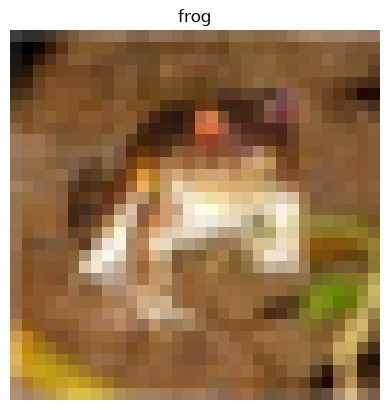

In [11]:
#3. Display an image
plt.imshow(x_train[0])

plt.title(class_names[y_train[0][0]])
plt.axis('off')

plt.show()

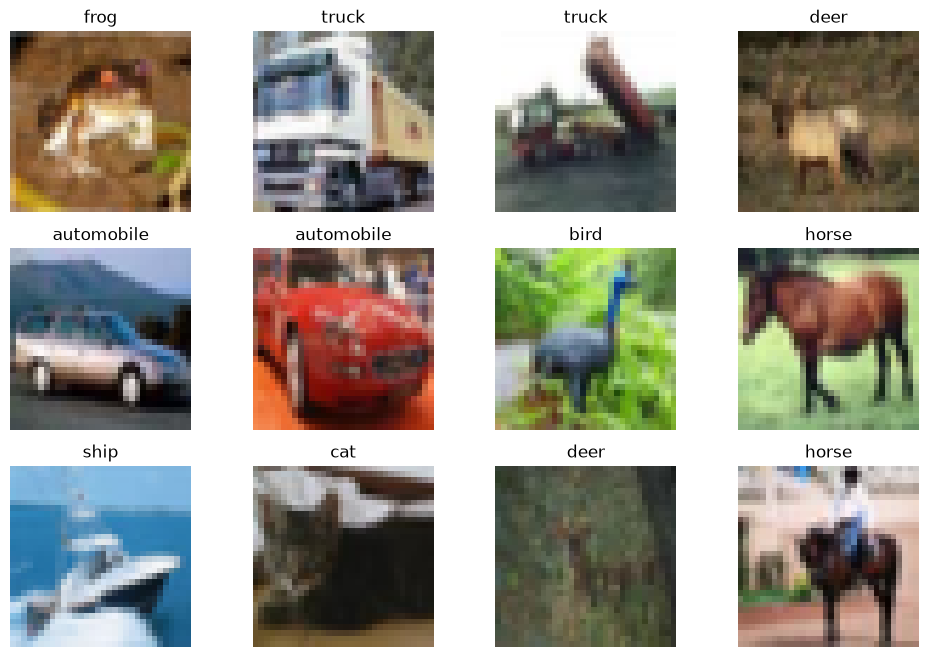

In [12]:
#4. Display multiple images
plt.figure(figsize=(12, 8))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    plt.imshow(x_train[i])

    label = y_train[i][0]

    plt.title(class_names[label])

    plt.axis('off')

plt.show()

In [13]:
#5. Inspect pixel values
print(x_train[0])

[[[ 59  62  63]
  [ 43  46  45]
  [ 50  48  43]
  ...
  [158 132 108]
  [152 125 102]
  [148 124 103]]

 [[ 16  20  20]
  [  0   0   0]
  [ 18   8   0]
  ...
  [123  88  55]
  [119  83  50]
  [122  87  57]]

 [[ 25  24  21]
  [ 16   7   0]
  [ 49  27   8]
  ...
  [118  84  50]
  [120  84  50]
  [109  73  42]]

 ...

 [[208 170  96]
  [201 153  34]
  [198 161  26]
  ...
  [160 133  70]
  [ 56  31   7]
  [ 53  34  20]]

 [[180 139  96]
  [173 123  42]
  [186 144  30]
  ...
  [184 148  94]
  [ 97  62  34]
  [ 83  53  34]]

 [[177 144 116]
  [168 129  94]
  [179 142  87]
  ...
  [216 184 140]
  [151 118  84]
  [123  92  72]]]


In [14]:
#6. Inspect pixel value
print(x_train[0])

[[[ 59  62  63]
  [ 43  46  45]
  [ 50  48  43]
  ...
  [158 132 108]
  [152 125 102]
  [148 124 103]]

 [[ 16  20  20]
  [  0   0   0]
  [ 18   8   0]
  ...
  [123  88  55]
  [119  83  50]
  [122  87  57]]

 [[ 25  24  21]
  [ 16   7   0]
  [ 49  27   8]
  ...
  [118  84  50]
  [120  84  50]
  [109  73  42]]

 ...

 [[208 170  96]
  [201 153  34]
  [198 161  26]
  ...
  [160 133  70]
  [ 56  31   7]
  [ 53  34  20]]

 [[180 139  96]
  [173 123  42]
  [186 144  30]
  ...
  [184 148  94]
  [ 97  62  34]
  [ 83  53  34]]

 [[177 144 116]
  [168 129  94]
  [179 142  87]
  ...
  [216 184 140]
  [151 118  84]
  [123  92  72]]]


In [15]:
print(x_train[0][0][0])

[59 62 63]


In [16]:
# 7 Normalize the images
x_train = x_train.astype('float32') / 255.0

x_test = x_test.astype('float32') / 255.0

In [17]:
#8 Check the values
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

Minimum: 0.0
Maximum: 1.0


In [18]:
# 9 split the training dataset further
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [19]:
print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

Training: (40000, 32, 32, 3)
Validation: (10000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


In [20]:
model = keras.Sequential([

    # First convolutional block
    layers.Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(32, 32, 3)
    ),

    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(
        128,
        (3, 3),
        activation='relu'
    ),

    # Classification layers
    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dense(10, activation='softmax')

])

C:\Users\bnnhy\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 4, 4, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [23]:
history = model.fit(

    x_train,
    y_train,

    epochs=15,

    batch_size=64,

    validation_data=(x_val, y_val)

)

Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.4234 - loss: 1.5734 - val_accuracy: 0.5268 - val_loss: 1.3323
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.5717 - loss: 1.2061 - val_accuracy: 0.6025 - val_loss: 1.1355
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.6360 - loss: 1.0374 - val_accuracy: 0.6430 - val_loss: 0.9999
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.6769 - loss: 0.9209 - val_accuracy: 0.6634 - val_loss: 0.9574
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.7104 - loss: 0.8323 - val_accuracy: 0.6838 - val_loss: 0.9011
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.7337 - loss: 0.7640 - val_accuracy: 0.7102 - val_loss: 0.8426
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.7567 - loss: 0.6921 - val_accuracy: 0.7022 - val_loss: 0.8579
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.7769 - loss: 0.6368 - val_a

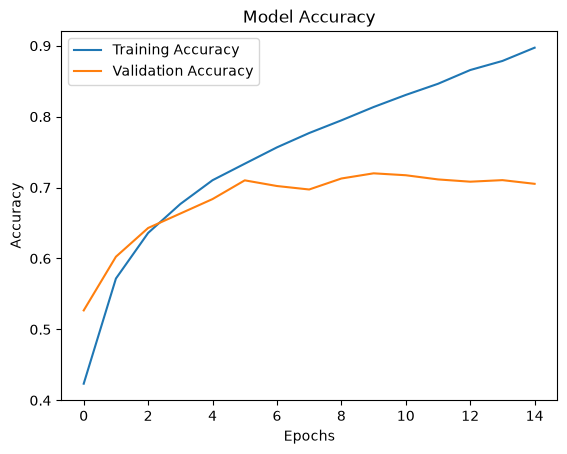

In [24]:
#Plot Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.title('Model Accuracy')

plt.legend()
plt.show()

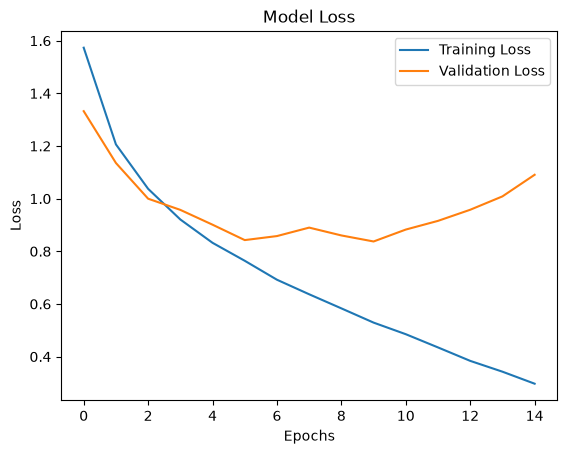

In [25]:
#Plot loss
plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.title('Model Loss')

plt.legend()
plt.show()

In [26]:
#Evaluate
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7024 - loss: 1.1206
Test Loss: 1.1206135749816895
Test Accuracy: 0.7024000287055969


In [27]:
#Generate predictions
predictions = model.predict(x_test)

predicted_classes = np.argmax(
    predictions,
    axis=1
)

actual_classes = y_test.flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [28]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    actual_classes,
    predicted_classes
)

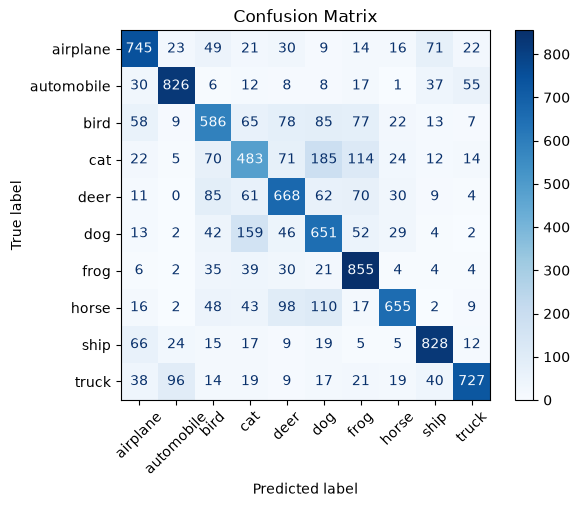

In [29]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap='Blues',
    xticks_rotation=45
)

plt.title('Confusion Matrix')

plt.show()

In [30]:
from sklearn.metrics import classification_report

print(
    classification_report(
        actual_classes,
        predicted_classes,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

    airplane       0.74      0.74      0.74      1000
  automobile       0.84      0.83      0.83      1000
        bird       0.62      0.59      0.60      1000
         cat       0.53      0.48      0.50      1000
        deer       0.64      0.67      0.65      1000
         dog       0.56      0.65      0.60      1000
        frog       0.69      0.85      0.76      1000
       horse       0.81      0.66      0.73      1000
        ship       0.81      0.83      0.82      1000
       truck       0.85      0.73      0.78      1000

    accuracy                           0.70     10000
   macro avg       0.71      0.70      0.70     10000
weighted avg       0.71      0.70      0.70     10000



In [31]:
#Augmentation layer
data_augmentation = keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomZoom(0.1)

])

In [32]:
layers.Dropout(0.5)

<Dropout name=dropout, built=True>

In [33]:
improved_model = keras.Sequential([

    data_augmentation,

    layers.Conv2D(
        32, (3, 3),
        padding='same',
        activation='relu',
        input_shape=(32, 32, 3)
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        padding='same',
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128, (3, 3),
        padding='same',
        activation='relu'
    ),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5),

    layers.Dense(10, activation='softmax')

])

C:\Users\bnnhy\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
improved_model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [35]:
improved_history = improved_model.fit(

    x_train,
    y_train,

    epochs=20,

    batch_size=64,

    validation_data=(x_val, y_val)

)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.3486 - loss: 1.7811 - val_accuracy: 0.4758 - val_loss: 1.4442
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.4541 - loss: 1.5153 - val_accuracy: 0.5408 - val_loss: 1.2788
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.5065 - loss: 1.3869 - val_accuracy: 0.5907 - val_loss: 1.1694
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.5426 - loss: 1.3020 - val_accuracy: 0.6193 - val_loss: 1.0750
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.5654 - loss: 1.2382 - val_accuracy: 0.5980 - val_loss: 1.1354
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.5788 - loss: 1.1981 - val_accuracy: 0.6284 - val_loss: 1.0603
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.5960 - loss: 1.1508 - val_accuracy: 0.6427 - val_loss: 1.0064
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.6089 - loss: 1.1111 - 

In [36]:
improved_loss, improved_accuracy = improved_model.evaluate(
    x_test,
    y_test
)

print("Improved Test Accuracy:", improved_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7118 - loss: 0.8276
Improved Test Accuracy: 0.7117999792098999


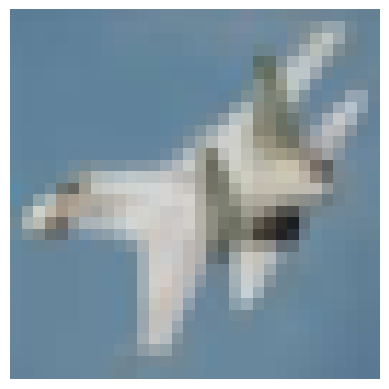

In [37]:
#Predict a new image
index = 10

image = x_test[index]

plt.imshow(image)

plt.axis('off')

plt.show()

In [38]:
#Generate prediction
prediction = improved_model.predict(
    np.expand_dims(image, axis=0)
)

predicted_class = np.argmax(prediction)

print("Predicted:", class_names[predicted_class])

print("Actual:", class_names[y_test[index][0]])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Predicted: airplane
Actual: airplane


In [39]:
#Display prediction confidence
for i, probability in enumerate(prediction[0]):

    print(
        class_names[i],
        round(float(probability) * 100, 2),
        "%"
    )

airplane 91.34 %
automobile 0.0 %
bird 2.75 %
cat 0.89 %
deer 2.4 %
dog 1.13 %
frog 0.0 %
horse 1.21 %
ship 0.26 %
truck 0.02 %


In [40]:
improved_model.save("image_classifier.keras")

In [42]:
loaded_model = keras.models.load_model(
    "image_classifier.keras"
)

In [43]:
loaded_model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7118 - loss: 0.8276


[0.8276084065437317, 0.7117999792098999]